# t-SNE

t-SNE (t-Distributed Stochastic Neighbor Embedding) is a non-linear machine learning technique used to visualize high-dimensional data in two or three dimensions

# For more information click the link below

https://docs.google.com/document/d/1vFMILR2beyf51q1MfmPYE1MdAwIikPVQYoXuN8ajMLk/edit?usp=sharing

# Notes and interview question and answer .

https://docs.google.com/document/d/1L3QRbNbJQ5m8xCs4CssSW684jzgAidwPILnPkHuW8o0/edit?usp=sharing

# Coding

In [6]:
from sklearn.datasets import load_digits
import numpy as np                                      # Numerical calculations
import pandas as pd                                     # Data manipulation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import load_digits                # Built-in handwritten digits dataset
from sklearn.preprocessing import StandardScaler        # Standardizes feature values
from sklearn.manifold import TSNE                       # t-SNE dimensionality reduction

# Load the dataset

In [7]:
digits = load_digits()                                  # Load the Digits dataset

X = digits.data                                         # 64 pixel features for each image
y = digits.target                                       # Digit labels from 0 to 9

print("X shape:", X.shape)                              # 1797 samples × 64 features
print("y shape:", y.shape)                              # 1797 labels

X shape: (1797, 64)
y shape: (1797,)


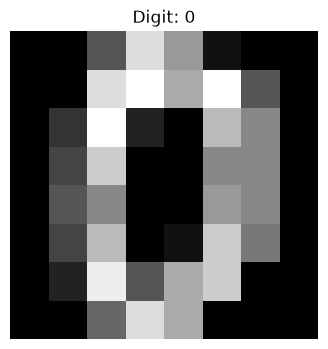

In [8]:
# Visualize the original digit

plt.figure(figsize=(4, 4))

plt.imshow(
    digits.images[0],                                   # Original 8×8 image
    cmap="gray"                                         # Display pixel intensity as grayscale
)

plt.title(f"Digit: {y[0]}")                             # Show the actual digit
plt.axis("off")                                         # Remove axis because this is an image

plt.show()

# Scale the features 

In [9]:
scaler = StandardScaler()                               # Creates the feature-scaling object

X_scaled = scaler.fit_transform(
    X                                                     # Standardize all 64 pixel features
)

print("Scaled shape:", X_scaled.shape)                  # Scaling changes values, not dimensions

Scaled shape: (1797, 64)


In [11]:
# Create the t-SNE model 

tsne = TSNE(
    n_components=2,                                     # Reduce 64 dimensions to 2 dimensions
    perplexity=30,                                      # Controls the effective size of local neighborhoods
    learning_rate="auto",                               # Automatically choose a suitable learning rate
    max_iter=1000,                                      # Number of optimization iterations
    random_state=42                                     # Makes the result reproducible
)

# Now let's  understnad the important parameters . 

# Apply t-SNE

In [13]:
X_tsne = tsne.fit_transform(
    X_scaled                                            # Learn the low-dimensional representation
)

print("Original shape:", X.shape)                       # 1797 × 64
print("t-SNE shape:", X_tsne.shape)                    # 1797 × 2

Original shape: (1797, 64)
t-SNE shape: (1797, 2)


# Visualize the t-SNE result 


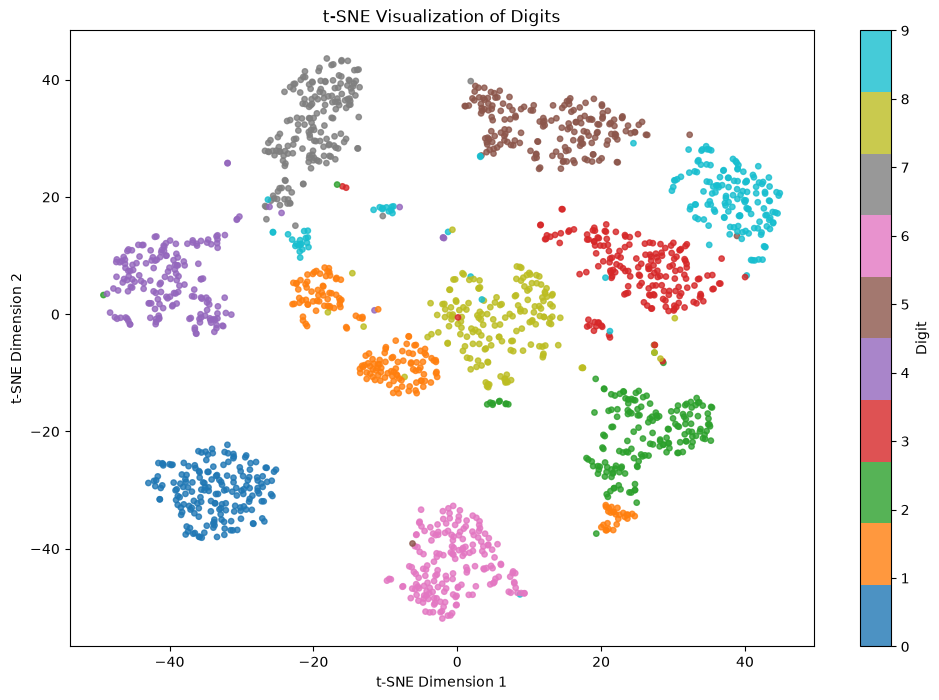

In [14]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_tsne[:, 0],                                      # First t-SNE dimension
    X_tsne[:, 1],                                      # Second t-SNE dimension
    c=y,                                                # Use labels only to color the visualization
    cmap="tab10",                                      # Different color for each digit
    s=15,                                               # Point size
    alpha=0.8                                           # Transparency of points
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE Visualization of Digits")

plt.colorbar(
    scatter,
    label="Digit"
)

plt.show()

 # Experiment with perplexity 
 `This is an important experiment because perplexity can significantly change the embeding`

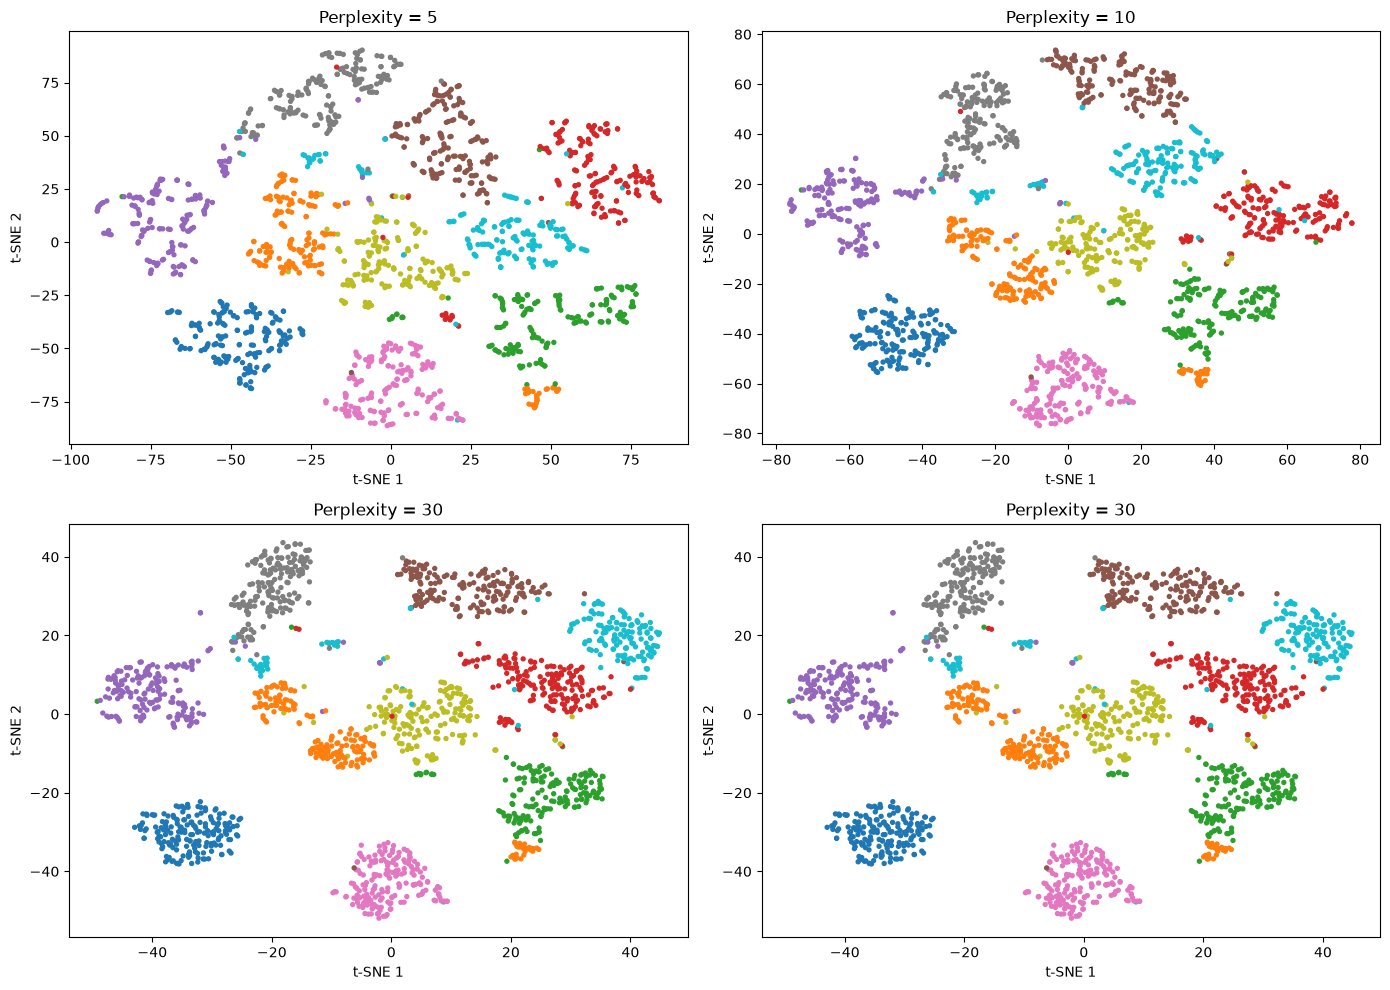

In [18]:
perplexities = [5, 10, 30, 30]                        # Different neighborhood sizes to compare

fig, axes = plt.subplots(
    2, 2,                                                # Create four visualization areas
    figsize=(14, 10)
)

for ax, perplexity in zip(axes.ravel(), perplexities):

    tsne = TSNE(
        n_components=2,                                  # Reduce to 2 dimensions
        perplexity=perplexity,                           # Change the neighborhood size
        learning_rate="auto",                            # Automatically select learning rate
        max_iter=1000,                                   # Optimization iterations
        random_state=42                                  # Keep initialization consistent
    )

    X_tsne_temp = tsne.fit_transform(
        X_scaled                                         # Generate embedding with this perplexity
    )

    scatter = ax.scatter(
        X_tsne_temp[:, 0],                               # First t-SNE dimension
        X_tsne_temp[:, 1],                               # Second t-SNE dimension
        c=y,                                              # Color according to digit
        cmap="tab10",
        s=8
    )

    ax.set_title(f"Perplexity = {perplexity}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

# t-SNE does NOT have explained variance 
`with PCA we can write `

In [17]:
# pca.explained_variance_ratio_

# Complete t-SNE code 

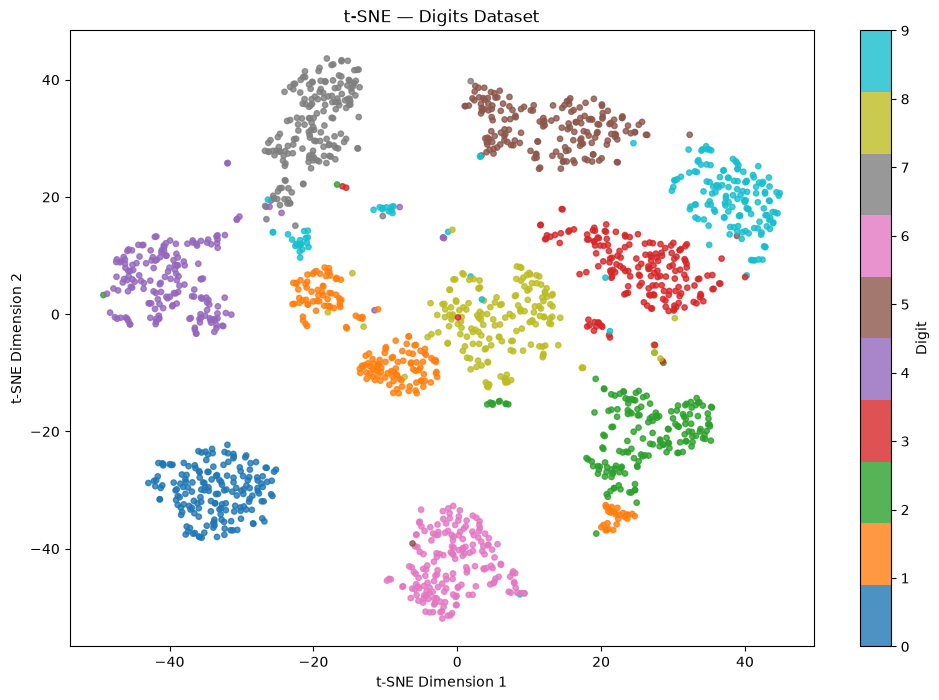

In [19]:
import numpy as np                                      # Numerical calculations
import pandas as pd                                     # Data manipulation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import load_digits                # Built-in handwritten digits dataset
from sklearn.preprocessing import StandardScaler        # Standardizes feature values
from sklearn.manifold import TSNE                       # t-SNE dimensionality reduction


digits = load_digits()                                  # Load the Digits dataset

X = digits.data                                         # 64 pixel features
y = digits.target                                       # Digit labels


scaler = StandardScaler()                               # Creates the scaler
X_scaled = scaler.fit_transform(
    X                                                     # Standardize the 64 features
)


tsne = TSNE(
    n_components=2,                                     # Reduce 64 dimensions to 2
    perplexity=30,                                      # Control local neighborhood size
    learning_rate="auto",                               # Automatically choose learning rate
    max_iter=1000,                                      # Number of optimization iterations
    random_state=42                                     # Reproducible result
)


X_tsne = tsne.fit_transform(
    X_scaled                                            # Learn the 2D nonlinear representation
)


plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_tsne[:, 0],                                      # t-SNE dimension 1
    X_tsne[:, 1],                                      # t-SNE dimension 2
    c=y,                                                # Labels used only for visualization
    cmap="tab10",
    s=15,
    alpha=0.8
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE — Digits Dataset")

plt.colorbar(
    scatter,
    label="Digit"
)

plt.show()